In [6]:
# ============================================================
# 01_exploration.ipynb — Data Exploration & Visualization
# Tasnim — Hotel Sentiment Project
# ============================================================

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

In [14]:

# ── 1. LOAD DATA ────────────────────────────────────────────
df = pd.read_csv("../data/raw/Hotel_Reviews.csv")
print("Shape:", df.shape)
print(df.head(2))

Shape: (515738, 17)
                                       Hotel_Address  \
0   s Gravesandestraat 55 Oost 1092 AA Amsterdam ...   
1   s Gravesandestraat 55 Oost 1092 AA Amsterdam ...   

   Additional_Number_of_Scoring Review_Date  Average_Score   Hotel_Name  \
0                           194    8/3/2017            7.7  Hotel Arena   
1                           194    8/3/2017            7.7  Hotel Arena   

  Reviewer_Nationality                                    Negative_Review  \
0              Russia    I am so angry that i made this post available...   
1             Ireland                                         No Negative   

   Review_Total_Negative_Word_Counts  Total_Number_of_Reviews  \
0                                397                     1403   
1                                  0                     1403   

                                     Positive_Review  \
0   Only the park outside of the hotel was beauti...   
1   No real complaints the hotel was great gr

In [15]:
# ── 2. BASIC STATS ──────────────────────────────────────────
print(df.dtypes)
print(df.isnull().sum())
print(df['Reviewer_Score'].describe())

Hotel_Address                                     str
Additional_Number_of_Scoring                    int64
Review_Date                                       str
Average_Score                                 float64
Hotel_Name                                        str
Reviewer_Nationality                              str
Negative_Review                                   str
Review_Total_Negative_Word_Counts               int64
Total_Number_of_Reviews                         int64
Positive_Review                                   str
Review_Total_Positive_Word_Counts               int64
Total_Number_of_Reviews_Reviewer_Has_Given      int64
Reviewer_Score                                float64
Tags                                              str
days_since_review                                 str
lat                                           float64
lng                                           float64
dtype: object
Hotel_Address                                    0
Additional_Number

In [16]:
# ── 3. COMBINE REVIEWS ──────────────────────────────────────
df['Negative_Review'] = df['Negative_Review'].replace('No Negative', '')
df['Positive_Review']  = df['Positive_Review'].replace('No Positive', '')
df['full_review'] = (df['Positive_Review'] + " " + df['Negative_Review']).str.strip()

In [17]:
# ── 4. SENTIMENT LABELS FROM SCORE ──────────────────────────
def label_sentiment(score):
    if score >= 8:   return 'Positive'
    elif score <= 5: return 'Negative'
    else:            return 'Neutral'

df['sentiment'] = df['Reviewer_Score'].apply(label_sentiment)
print(df['sentiment'].value_counts())

sentiment
Positive    335646
Neutral     149389
Negative     30703
Name: count, dtype: int64


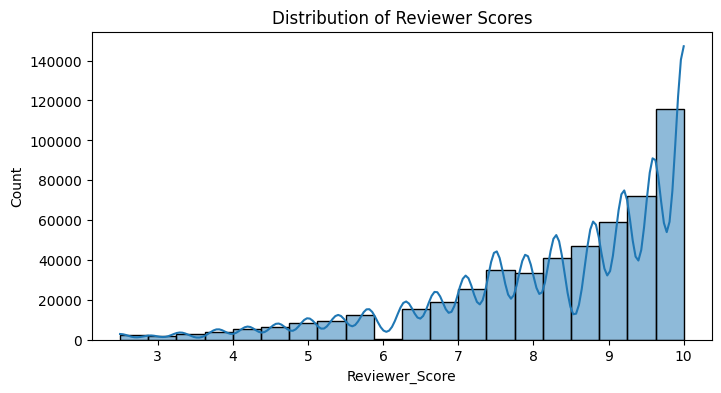

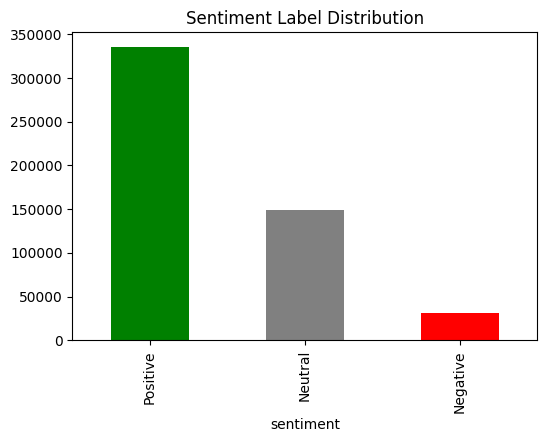

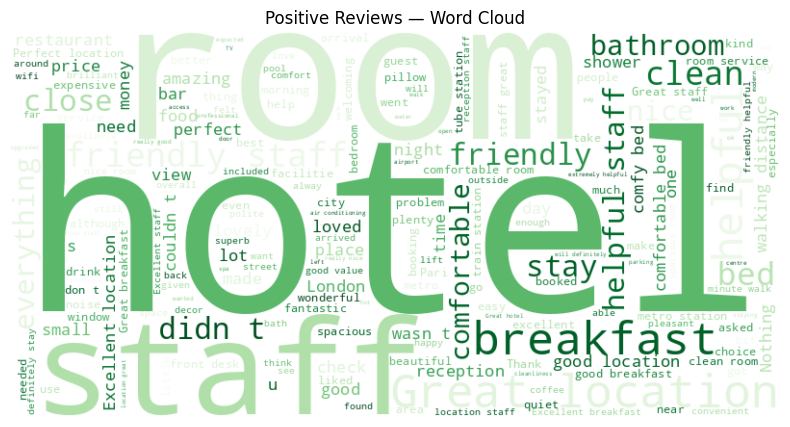

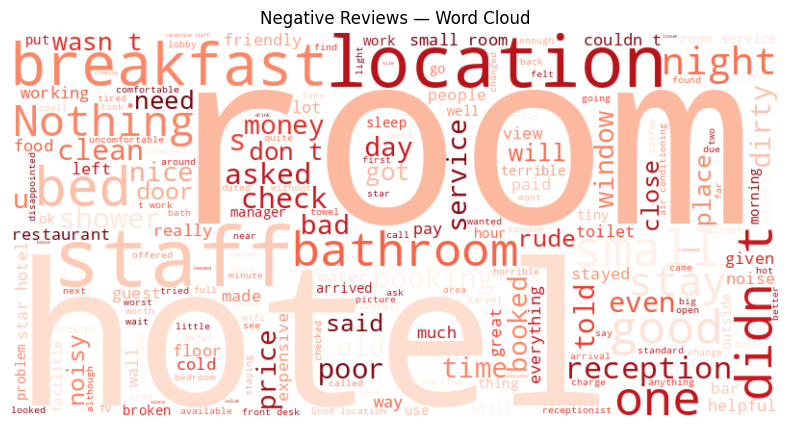

In [ ]:

# ── 5. VISUALIZATIONS ───────────────────────────────────────
# Rating histogram
plt.figure(figsize=(8,4))
sns.histplot(df['Reviewer_Score'], bins=20, kde=True)
plt.title('Distribution of Reviewer Scores')
plt.savefig('../results/visualizations/rating_distribution.png')
plt.show()

# Sentiment distribution
plt.figure(figsize=(6,4))
df['sentiment'].value_counts().plot(kind='bar', color=['green','gray','red'])
plt.title('Sentiment Label Distribution')
plt.savefig('../results/visualizations/sentiment_distribution.png')
plt.show()

# Word clouds
for sentiment, color in [('Positive','Greens'), ('Negative','Reds')]:
    text = " ".join(df[df['sentiment'] == sentiment]['full_review'].dropna())
    wc = WordCloud(width=800, height=400,
                   background_color='white',
                   colormap=color).generate(text)
    plt.figure(figsize=(10,5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'{sentiment} Reviews — Word Cloud')
    plt.savefig(f'../results/visualizations/wordcloud_{sentiment.lower()}.png')
    plt.show()